# Exploratory analysis to figure out filtering, indels etc.
We use the R and tidyverse setup (dplyr, ggplot) for this. Writing in a jupyter notebook for quick future reference.

Author: Prashant K ;
Date: 6/Oct/26


In [1]:
# import libraries
library(tidyverse)

# import data
base_path <- "3R5library_madison/"
data <- read_tsv(str_c(base_path, "variant_data_parsed.tsv"))

summarise(data, count = n(), .by = Nham_nt) |> print()
cat("total rows in data: ", nrow(data), "\n")

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.1     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.3     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors
Rows: 1901795 Columns: 27
── Column specification ────────────────────────────────────────────────────────
Delimiter: "\t"
chr  (1): nt_seq
dbl (26): Nham_nt, Input3AptzUra30_e1_s0_bNA_percent, UraTheo30_e1_s1_b1_per...

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


# A tibble: 27 × 2
   Nham_nt  count
     <dbl>  <int>
 1       0      1
 2      16  74105
 3      NA 605014
 4      18  44412
 5      12  97475
 6      13  92796
 7      11  94920
 8      15  79529
 9       5  50754
10      17  62390
# ℹ 17 more rows
total rows in data:  1901795 


## Filter and cleanup
Discard singletons and zero counts in input column. 
_This is important because the enrichment and leak calculations involve division by the input count, and we want to avoid division by zero or very small numbers that could skew the results._

Showing the distribution of variants across hamming distance (and indels)

In [4]:
# filter for input counts >= 2
filtered_data <- data |>
  filter(Input3AptzUra30_e1_s0_bNA_count >= 2)

summarise(filtered_data, count = n(), .by = Nham_nt) |> print()
cat("total rows in filtered data: ", nrow(filtered_data), "\n")

# A tibble: 27 × 2
   Nham_nt count
     <dbl> <int>
 1       0     1
 2      16  2091
 3      NA 26204
 4      18  1263
 5      12  4016
 6      13  3534
 7      11  4345
 8      15  2651
 9       5  4623
10      17  1771
# ℹ 17 more rows
total rows in filtered data:  94353 


### Indel handling
**Goal** is to keep the number of worthless indels low (< 1/2 of SNPs>). _This is because the SNPs have been QCed by the masking protocol but indels have a more free reign in showing spurious stuff_

In [6]:
# split the data into SNVs and indels and
# filter the indels more stringently for > 50 in Input count or enriched counts
snvs <- filtered_data |> filter(!is.na(Nham_nt))

indels <- filtered_data |>
  filter(is.na(Nham_nt)) |>
  filter(if_any(ends_with("count"), ~ . >= 50))

# combine the filtered SNVs and indels back into one dataset
filtered_indels_stringent <- bind_rows(snvs, indels)

summarise(filtered_indels_stringent, count = n(), .by = Nham_nt) |> print()
cat("total rows in filtered data (stringent indel filtering): ",
    nrow(filtered_indels_stringent), "\n")

cat("before filtering = ", nrow(filter(data, is.na(Nham_nt))), " indels\n")
cat("after filtering = ", nrow(filter(filtered_indels_stringent, is.na(Nham_nt))), " indels\n")

# A tibble: 27 × 2
   Nham_nt count
     <dbl> <int>
 1       0     1
 2      16  2091
 3      18  1263
 4      12  4016
 5      13  3534
 6      11  4345
 7      15  2651
 8       5  4623
 9      17  1771
10       1   821
# ℹ 17 more rows
total rows in filtered data (stringent indel filtering):  70895 
before filtering =  605014  indels
after filtering =  2746  indels


In [ ]:
# # save the data 
# write_tsv(filtered_indels_stringent, 
#           file = str_c(base_path, "filtered_indels_stringent.tsv"))

Above line prints the number of rows for each unique value in the 'Nham_nt' column.

## Plotting
### Distribution of read counts across samples
Plotting small multiples for each sample (input, enriched various, etc.). _Cast to long format helps with plotting each sample in a different colour_

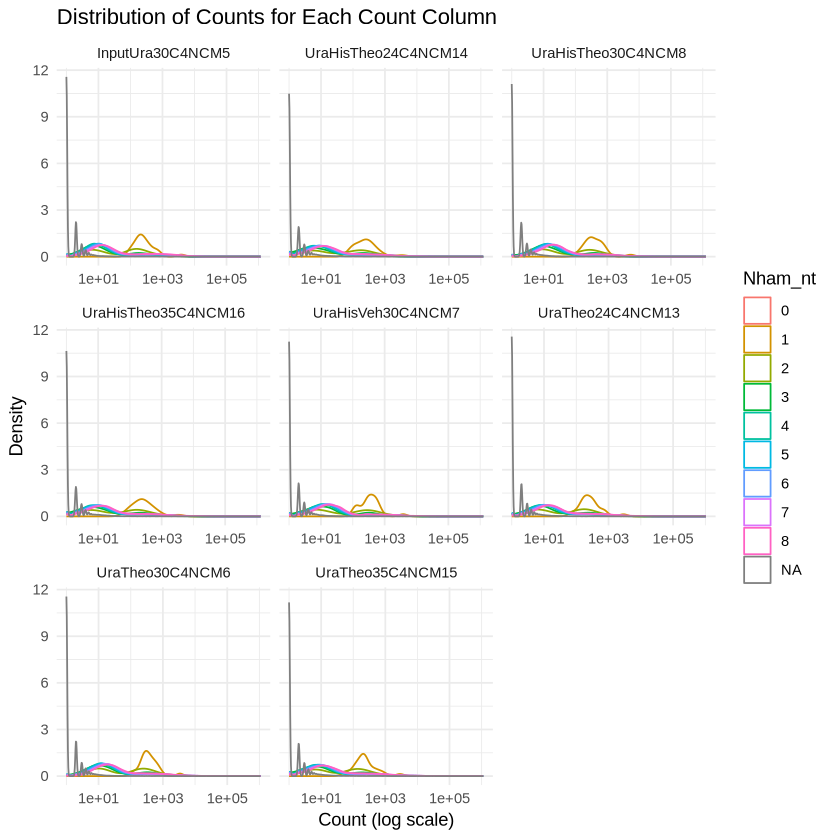

In [ ]:
# Convert the data into long format with each count column
# (discard the percentage and freq cols)
long_data <- data %>%
  select(-ends_with("_percent"), -ends_with("_freq")) %>%
  pivot_longer(
    cols = ends_with("_count"),
    names_to = "count_type",
    values_to = "count"
  ) %>%
  mutate(count_type = sub("_.*$", "", count_type)) %>%  
  mutate(Nham_nt = as_factor(Nham_nt)) %>%
  group_by(Nham_nt, count_type)

# Plot the distribution of counts for each count column in small multiples
distribution_plot <-
  ggplot(long_data, aes(x = count, colour = Nham_nt)) +
  facet_wrap(~count_type, scales = "free_x") +
  geom_density() +
  scale_x_log10() +
  labs(
    title = "Distribution of Counts for Each Count Column",
    x = "Count (log scale)",
    y = "Density"
  ) +
  theme_minimal()

suppressWarnings(print(distribution_plot))

Same thing for filtered data

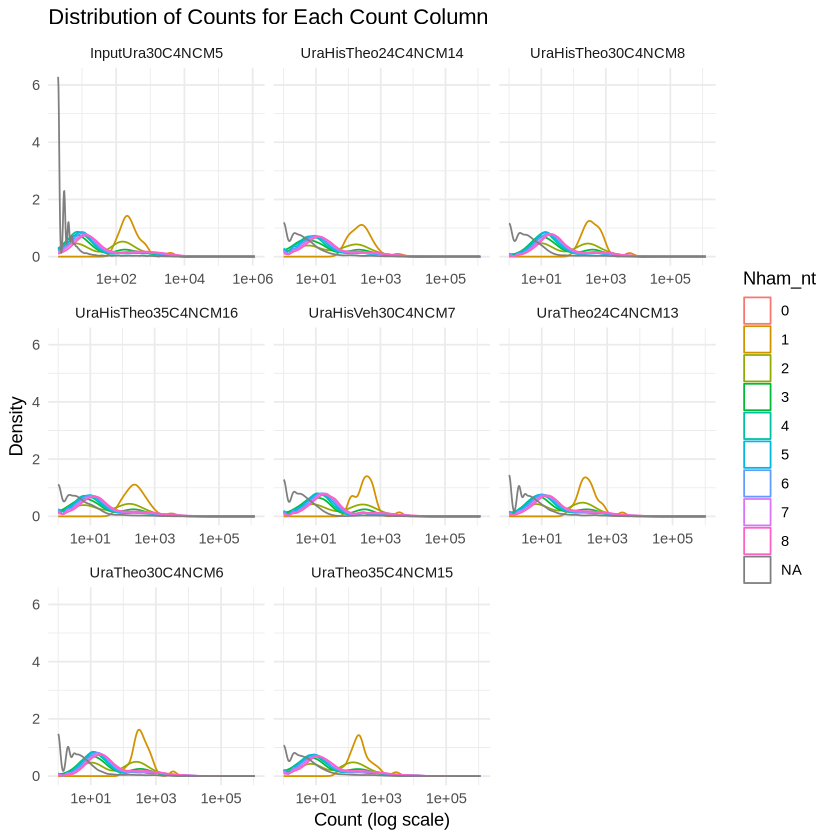

In [ ]:
# same thing for filtered data
filtered_long <- filtered_data %>%
  select(-ends_with("_percent"), -ends_with("_freq")) %>%
  pivot_longer(
    cols = ends_with("_count"),
    names_to = "count_type",
    values_to = "count"
  ) %>%
  mutate(count_type = sub("_.*$", "", count_type)) %>%  
  mutate(Nham_nt = as_factor(Nham_nt)) %>%
  group_by(Nham_nt, count_type)

# Plot the distribution of counts for each count column in small multiples
distribution_filtered <-
  ggplot(filtered_long, aes(x = count, colour = Nham_nt)) +
  facet_wrap(~count_type, scales = "free_x") +
  geom_density() +
  scale_x_log10() +
  labs(
    title = "Distribution of Counts for Each Count Column",
    x = "Count (log scale)",
    y = "Density"
  ) +
  theme_minimal()

suppressWarnings(print(distribution_filtered))

### Stringent filtered indels
Same thing for stringently filtered indels in the data

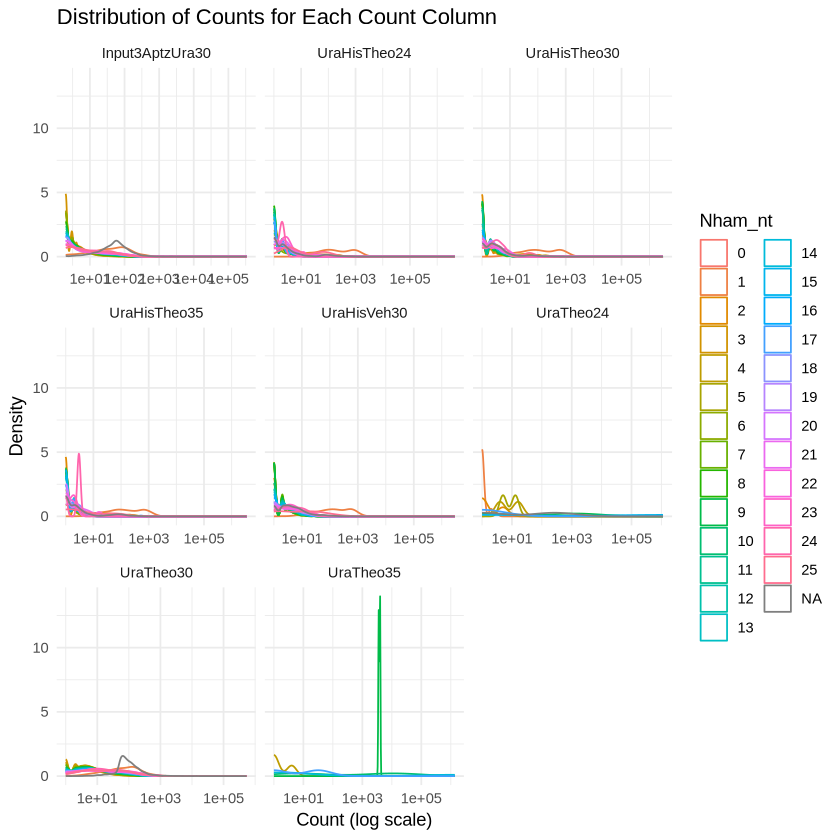

In [7]:
# same plot for filtered_indels_stringent
filtered_indels_stringent_long <- filtered_indels_stringent %>%
  select(-ends_with("_percent"), -ends_with("_freq")) %>%
  pivot_longer(
    cols = ends_with("_count"),
    names_to = "count_type",
    values_to = "count"
  ) %>%
  mutate(count_type = sub("_.*$", "", count_type)) %>%  
  mutate(Nham_nt = as_factor(Nham_nt)) %>%
  group_by(Nham_nt, count_type)

# Plot the distribution of counts for each count column in small multiples
distribution_filtered_stringent <-
  ggplot(filtered_indels_stringent_long, aes(x = count, colour = Nham_nt)) +
  facet_wrap(~count_type, scales = "free_x") +
  geom_density() +
  scale_x_log10() +
  labs(
    title = "Distribution of Counts for Each Count Column",
    x = "Count (log scale)",
    y = "Density"
  ) +
  theme_minimal()

suppressWarnings(print(distribution_filtered_stringent))

### Debug: nham 1 
Why is the nham=1 so differently distributed; doesn't have any low count ones (< 100)

### Partition betwen SNPs and indels
Show the read count per variant between SNPs (nham all numbers) and indels (nham NA)

Warning message in scale_y_log10():
“log-10 transformation introduced infinite values.”
Warning message:
“Removed 413466 rows containing non-finite outside the scale range
(`stat_boxplot()`).”


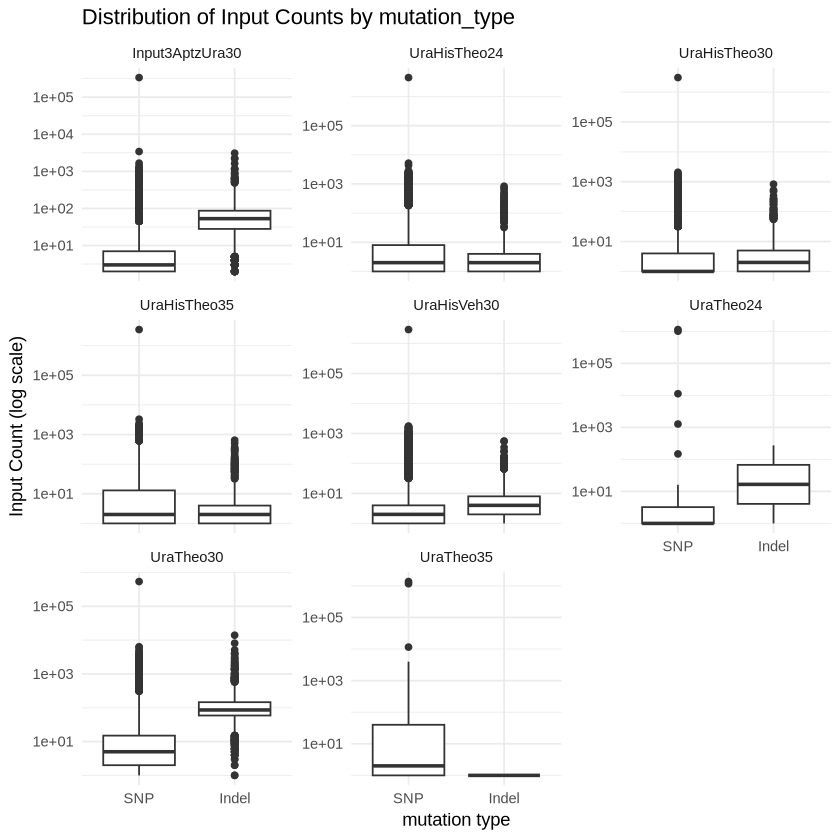

In [10]:
mutation_type_data <-
  mutate(filtered_indels_stringent_long,
          mutation_type = as_factor(if_else(is.na(Nham_nt), "Indel", "SNP"))
)

{ ggplot(mutation_type_data, aes(x = mutation_type, y = count)) +
geom_boxplot() + 
# geom_jitter(width = 0.2, alpha = 0.1) + # show individual points with some jitter
# small multiples
facet_wrap(~ count_type, scales = "free_y") +
scale_y_log10() +
labs(
  title = "Distribution of Input Counts by mutation_type",
  x = "mutation type",
  y = "Input Count (log scale)"
) +
  theme_minimal() } |>
  suppressWarnings(print(.))

# Indel analysis

In [11]:
# filter indels only and plot the distribution of counts for each count column in small multiples
indel_data <- data %>%
  filter(is.na(Nham_nt))

indel_long <- long_data %>%
  filter(is.na(Nham_nt))

# plot the distribution of counts for indels only
indel_distribution_plot <-
  ggplot(indel_long, aes(x = count, colour = count_type)) +
  geom_density() +
  scale_x_log10() +
  labs(
    title = "Distribution of Counts for Indels Only",
    x = "Count (log scale)",
    y = "Density"
  ) +
  theme_minimal()

indel_distribution_plot

# Plot input vs 25 scatterplot: only show points where input count >= 2
scatter_plot <-
  ggplot(
    data,
    aes(
      x = `InputUra30C4NCM5_e1_s0_bNA_count`,
      y = `neg25uM5fDUTheoCM_e1_s1_b1_count`
    )
  ) +
  geom_point() +
  scale_x_log10() +
  scale_y_log10() +
  labs(title = "Input vs 25", x = "Input Count", y = "25 selection Count") +
  theme_minimal()

scatter_plot

ERROR: Error: object 'long_data' not found


## Selecting indels

In [ ]:
count(indel_data)

# show indels with > 2 input counts
input_indels <- indel_data %>%
  filter(if_all(matches("Input.*_count$"), ~ .x > 2)) %>%
  count() %>%
  print()

# filter to > 2 in each count column
indel_filtered <- indel_data %>%
  filter_at(vars(ends_with("_count")), all_vars(. >= 2))

# save these filtered rows to a new file
# write_tsv(indel_filtered, "../filtered_indels_2+_counts.tsv")

n
<int>
19695


# A tibble: 1 × 1
      n
  <int>
1  2455


## Very significant indels

In [ ]:
# Show all the NA Nham_nt values where the selected count is > 1000
print("NA Nham_nt values where 'neg25uM5fDUTheoCM_e1_s1_b1_count' > 1000:")
indels_1000 <-
  data %>%
  filter(is.na(Nham_nt) & `neg25uM5fDUTheoCM_e1_s1_b1_count` > 1000) %>%
  print()

# save these filtered rows to a new file
# write_tsv(indels_1000, "../filtered_indels_high_enriched_counts.tsv")

[1] "NA Nham_nt values where 'neg25uM5fDUTheoCM_e1_s1_b1_count' > 1000:"
# A tibble: 21 × 18
   nt_seq                  Nham_nt InputCM_e1_s0_bNA_pe…¹ neg25uM5fDUTheoCM_e1…²
   <chr>                     <dbl>                  <dbl>                  <dbl>
 1 ttctccttcggtacatccagct…      NA               0.00569                  3.68  
 2 ttctccttcggtacatccagct…      NA               0.00482                  0.576 
 3 ttctccttggtacatccagctg…      NA               0.00180                  0.0199
 4 ttctccttcggtacatccagct…      NA               0.00124                  0.566 
 5 ttctccttcggtacatccagct…      NA               0.000778                 0.357 
 6 ttctccttcggtacatccagct…      NA               0.000602                 0.0178
 7 ttctccttcggtacatccagct…      NA               0.000559                 0.170 
 8 ttctccttcggtacatccagct…      NA               0.000493                 0.399 
 9 ttctccttcggtacatccagct…      NA               0.000482                 0.0187
10 ttctccttcggta